# Part 4: Seaborn Deep Dive
**Course Notes Reference:** Part 11

Topics covered:
1. Seaborn's 3 plot families (Relational, Distribution, Categorical) + Matrix/Multi
2. Axes-level vs Figure-level functions (`relplot`, `displot`, `catplot` with `col` / `row` facets)
3. Categorical plots in detail: `stripplot`, `swarmplot`, `boxplot`, `violinplot`, `barplot`, `pointplot`, `countplot`
4. Themes, contexts & colour-blind safe palettes (`sns.set_theme`, `sns.despine`, `colorblind`)
5. Other useful Seaborn plots: `ecdfplot`, `rugplot`, `clustermap`


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
df = pd.read_csv("vgsales.csv").dropna(subset=["Year", "Publisher"]).copy()
df["Year"] = df["Year"].astype(int)
df["log_sales"] = np.log1p(df["Global_Sales"])


## 1. Figure-Level Functions & Faceting (`displot`, `relplot`, `catplot`)


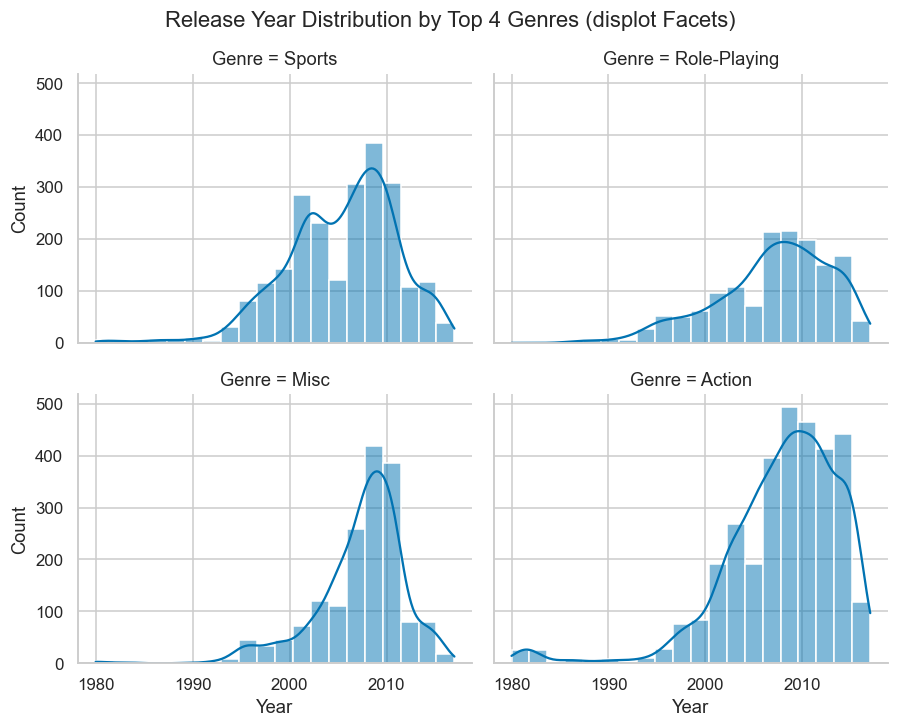

In [2]:
top4_genres = df["Genre"].value_counts().head(4).index
sub4 = df[df["Genre"].isin(top4_genres)]

# displot with col= and col_wrap=
g = sns.displot(data=sub4, x="Year", col="Genre", col_wrap=2, bins=20, height=3.2, aspect=1.3, kde=True)
g.figure.suptitle("Release Year Distribution by Top 4 Genres (displot Facets)", y=1.03)
plt.show()


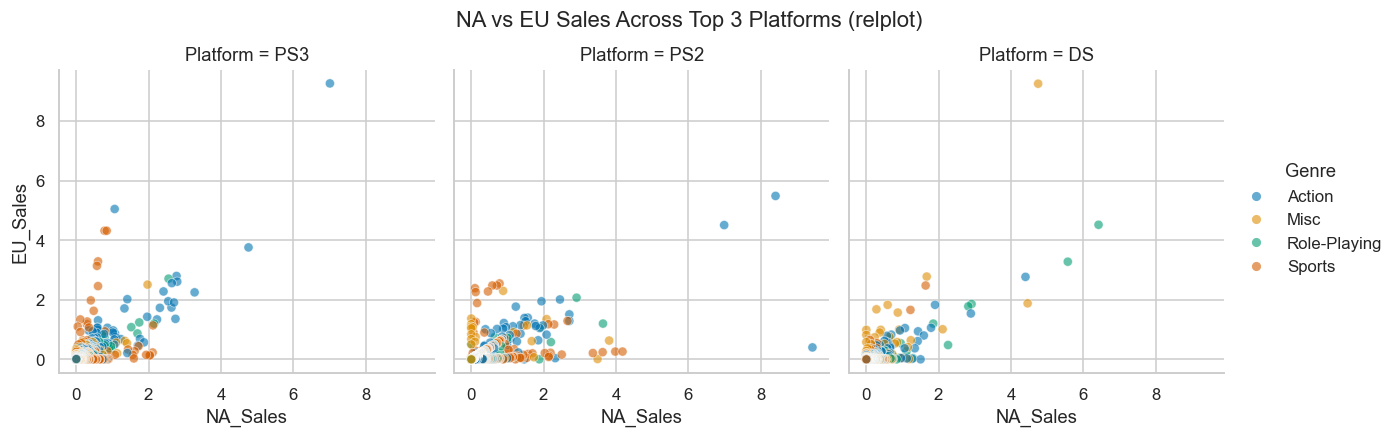

In [3]:
# relplot: scatter faceted by Platform
top3_plat = df["Platform"].value_counts().head(3).index
sub_p = sub4[sub4["Platform"].isin(top3_plat)]

g = sns.relplot(data=sub_p, x="NA_Sales", y="EU_Sales", hue="Genre", col="Platform", kind="scatter", height=3.8, alpha=0.6)
g.figure.suptitle("NA vs EU Sales Across Top 3 Platforms (relplot)", y=1.04)
plt.show()


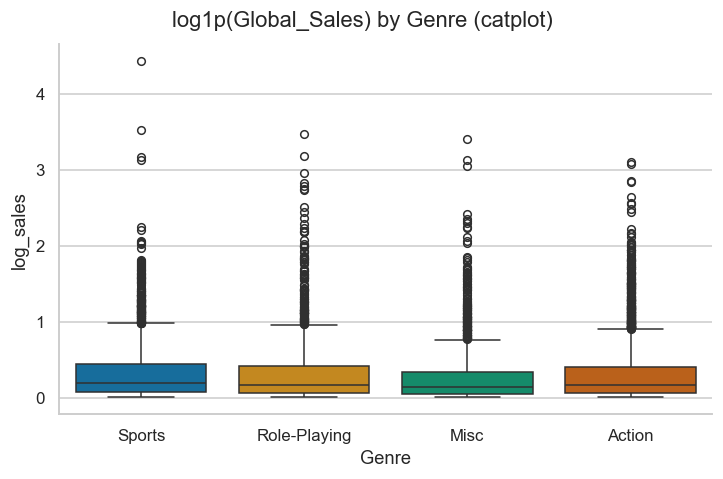

In [4]:
# catplot: box plot across genres
g = sns.catplot(data=sub4, x="Genre", y="log_sales", kind="box", height=4.2, aspect=1.6, hue="Genre", legend=False)
g.figure.suptitle("log1p(Global_Sales) by Genre (catplot)", y=1.03)
plt.show()


## 2. Categorical Plots in Detail (`stripplot`, `swarmplot`, `pointplot`)


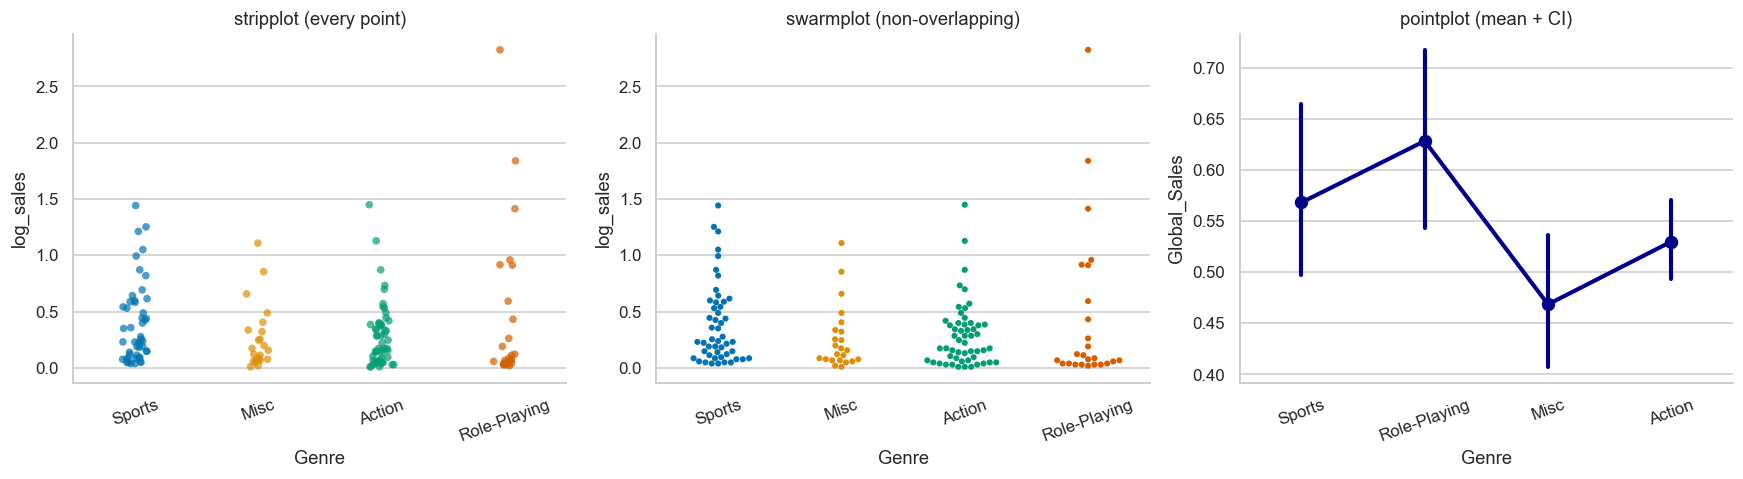

In [5]:
# Sample 150 games from top 4 genres so stripplot & swarmplot stay clean and fast
small_sample = sub4.sample(150, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.stripplot(data=small_sample, x="Genre", y="log_sales", hue="Genre", legend=False, alpha=0.7, ax=axes[0])
axes[0].set_title("stripplot (every point)")
axes[0].tick_params(axis="x", rotation=20)

sns.swarmplot(data=small_sample, x="Genre", y="log_sales", hue="Genre", legend=False, size=4, ax=axes[1])
axes[1].set_title("swarmplot (non-overlapping)")
axes[1].tick_params(axis="x", rotation=20)

sns.pointplot(data=sub4, x="Genre", y="Global_Sales", ax=axes[2], color="darkblue")
axes[2].set_title("pointplot (mean + CI)")
axes[2].tick_params(axis="x", rotation=20)

sns.despine()
plt.tight_layout()
plt.show()


## 3. Other Useful Seaborn Plots: `ecdfplot`, `rugplot`, `clustermap`


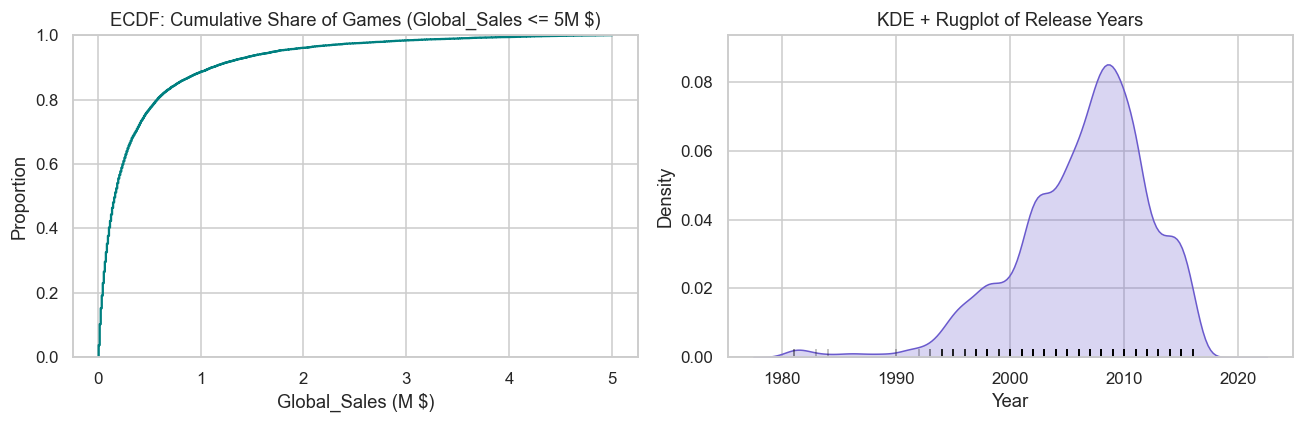

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.ecdfplot(df[df["Global_Sales"] <= 5]["Global_Sales"], ax=axes[0], color="teal")
axes[0].set_title("ECDF: Cumulative Share of Games (Global_Sales <= 5M $)")
axes[0].set_xlabel("Global_Sales (M $)")

sns.kdeplot(df["Year"], ax=axes[1], fill=True, color="slateblue")
sns.rugplot(df["Year"].sample(500, random_state=42), ax=axes[1], color="black", alpha=0.3)
axes[1].set_title("KDE + Rugplot of Release Years")

plt.tight_layout()
plt.show()


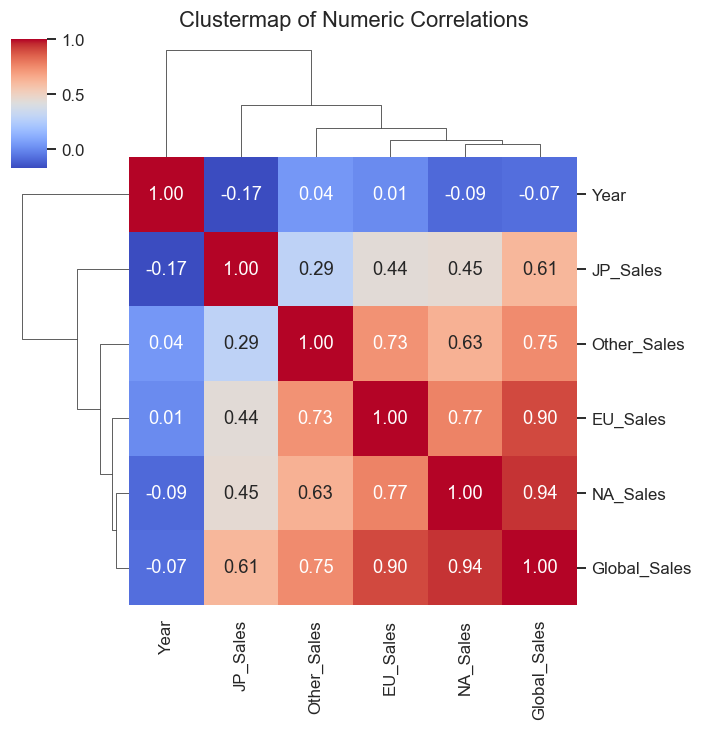

In [7]:
# Clustermap: groups similar rows/columns by correlation
corr = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales", "Year"]].corr()
g = sns.clustermap(corr, annot=True, fmt=".2f", cmap="coolwarm", figsize=(6.5, 6.5))
g.figure.suptitle("Clustermap of Numeric Correlations", y=1.02)
plt.show()
